# Lab Task 05 – Spatial Filtering and Convolution

**Name:** Kamal Ali Akmal  **Roll No:** 2024-SE-38  
**Course:** Digital Image Processing Lab – Department of Software Engineering, UAJK  
**Instructor:** Engr. Fahad Nisar | **Semester:** 5th | **Session:** 2024-28 (SE)

**Objective:** implement 2-D convolution from first principles, then use mean, Gaussian and median filters to remove noise from real images, checking the results by hand and against OpenCV.

**Rules followed throughout (from the lab sheet):** R1 same-size output with reflect padding · R2 float64 maths, `round`+`clip` to uint8 only at the end · R3 smoothing kernels sum to 1 · R4 odd kernel sizes 3/5/7 · R5 noise with `seed=5` · R6 every filtered image is judged against the **clean original**, never the noisy one.

## 1. Setup and the three test images
`camera`, `coins` and `chelsea` come from `skimage.data`; `chelsea` (a colour photo) is converted to grayscale. The originals are made read-only and compared with backup copies at the end, so they stay unchanged.

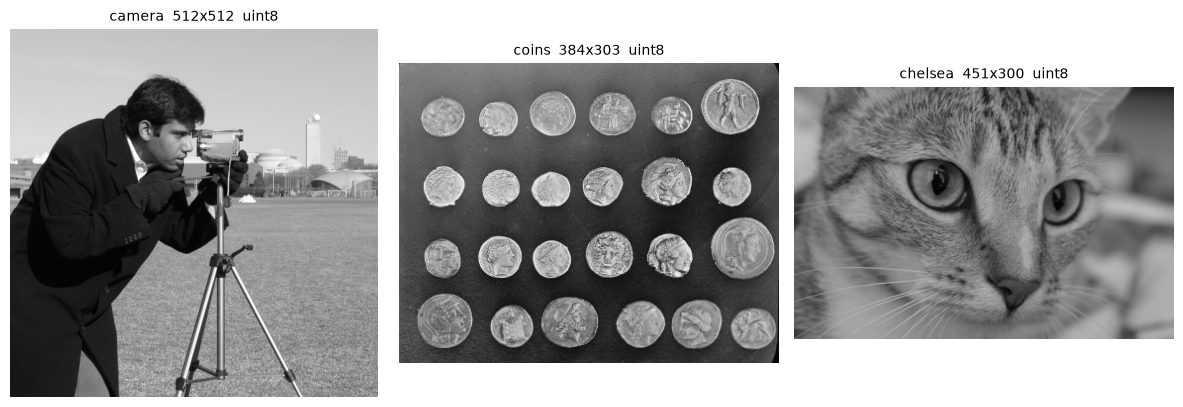

camera   shape=(512, 512) dtype=uint8 min=0 max=255
coins    shape=(303, 384) dtype=uint8 min=1 max=252
chelsea  shape=(300, 451) dtype=uint8 min=4 max=194


In [1]:
import hashlib
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

images = {
    "camera":  data.camera(),
    "coins":   data.coins(),
    "chelsea": cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2GRAY),   # colour -> grayscale
}
backup = {k: v.copy() for k, v in images.items()}
for v in images.values():
    v.flags.writeable = False                                      # originals cannot be modified
names = list(images)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, n in zip(axes, names):
    ax.imshow(images[n], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{n}  {images[n].shape[1]}x{images[n].shape[0]}  {images[n].dtype}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()
for n, v in images.items():
    print(f"{n:8s} shape={v.shape} dtype={v.dtype} min={v.min()} max={v.max()}")

## 2. `conv2d_loop` – 2-D convolution with nested loops
Steps (R1, R2): (1) **flip** the kernel in both directions (true convolution, not correlation); (2) pad the image by `k//2` on every side with **reflect** padding; (3) for every output pixel compute the weighted sum of its neighbourhood with explicit loops in **float64**; (4) return a float64 array of the same size as the input.

`to_uint8` is the only place where values are rounded and clipped to 0–255 (R2).

In [2]:
def to_uint8(a):
    """Round, clip to 0-255 and convert to uint8 (the only float -> uint8 step, R2)."""
    return np.clip(np.rint(a), 0, 255).astype(np.uint8)

def conv2d_loop(img, kernel):
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    if img.ndim != 2 or kernel.ndim != 2:
        raise ValueError("img and kernel must both be 2-D arrays")
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError(f"kernel dimensions must be odd, got {kh}x{kw}")
    flipped = kernel[::-1, ::-1]                                  # true convolution: flip both axes
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode="reflect")    # reflect padding (R1)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for y in range(H):                                            # every output pixel ...
        for x in range(W):
            total = 0.0
            for i in range(kh):                                   # ... is a weighted sum of its neighbourhood
                for j in range(kw):
                    total += padded[y + i, x + j] * flipped[i, j]
            out[y, x] = total
    return out

# quick sanity test on a tiny array: an impulse convolved with a kernel reproduces the kernel (not its mirror image)
impulse = np.zeros((5, 5)); impulse[2, 2] = 1
k_test = np.arange(1, 10, dtype=float).reshape(3, 3)
print(conv2d_loop(impulse, k_test)[1:4, 1:4])

[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]


## 3. Verifying `conv2d_loop` against OpenCV
`cv2.filter2D` computes **correlation**, so it is fed the *flipped* kernel to obtain convolution; `BORDER_REFLECT_101` is OpenCV's name for NumPy's `mode="reflect"`. An **asymmetric** kernel is used on purpose: with a symmetric kernel, flipping would make no difference and a missing flip would go unnoticed.

In [3]:
import time
cam = images["camera"]
asym = np.array([[1, 2, 0],
                 [4, 0, -1],
                 [0, -2, -3]], dtype=np.float64)                    # asymmetric test kernel

t = time.time()
mine = conv2d_loop(cam, asym)
print(f"conv2d_loop on camera {cam.shape} took {time.time() - t:.1f} s; output dtype={mine.dtype}, shape={mine.shape}")

cv_conv = cv2.filter2D(cam.astype(np.float64), cv2.CV_64F, asym[::-1, ::-1], borderType=cv2.BORDER_REFLECT_101)
cv_corr = cv2.filter2D(cam.astype(np.float64), cv2.CV_64F, asym,            borderType=cv2.BORDER_REFLECT_101)
print(f"largest |conv2d_loop - OpenCV (flipped kernel)| = {np.abs(mine - cv_conv).max():.3e}")
print(f"largest |conv2d_loop - OpenCV (kernel NOT flipped, i.e. correlation)| = {np.abs(mine - cv_corr).max():.3f}   <- proves the flip matters")
print("same shape as input:", mine.shape == cam.shape)

# real smoothing filters: 3x3 mean on camera, 5x5 Gaussian on coins
mean3 = np.full((3, 3), 1 / 9)
a = to_uint8(conv2d_loop(cam, mean3))
b = cv2.blur(cam, (3, 3), borderType=cv2.BORDER_REFLECT_101)
print(f"\n3x3 mean on camera : conv2d_loop vs cv2.blur         -> largest difference = {int(np.abs(a.astype(int) - b.astype(int)).max())} grey level(s)")
g5 = np.outer(cv2.getGaussianKernel(5, 0), cv2.getGaussianKernel(5, 0))
coins = images["coins"]
c = conv2d_loop(coins, g5)
d = cv2.GaussianBlur(coins.astype(np.float64), (5, 5), 0, borderType=cv2.BORDER_REFLECT_101)
print(f"5x5 Gaussian on coins: conv2d_loop vs cv2.GaussianBlur -> largest difference = {np.abs(c - d).max():.3e}")

conv2d_loop on camera (512, 512) took 5.1 s; output dtype=float64, shape=(512, 512)
largest |conv2d_loop - OpenCV (flipped kernel)| = 0.000e+00
largest |conv2d_loop - OpenCV (kernel NOT flipped, i.e. correlation)| = 2851.000   <- proves the flip matters
same shape as input: True

3x3 mean on camera : conv2d_loop vs cv2.blur         -> largest difference = 0 grey level(s)
5x5 Gaussian on coins: conv2d_loop vs cv2.GaussianBlur -> largest difference = 0.000e+00


## 4. Noise functions, filters and kernels

* `add_gaussian_noise(img, sigma=20, seed=5)` adds zero-mean Gaussian noise (computed in float64, then rounded and clipped, R2).
* `add_salt_pepper(img, amount=0.05, seed=5)` turns a fraction `amount` of the pixels into noise – half become 0 (pepper), half 255 (salt).
* Both use `np.random.default_rng(seed)`, so every run (and every student) gets the same noisy images (R5).
* **Mean** kernel: all weights `1/k²`. **Gaussian** kernel: the same discrete weights `cv2.GaussianBlur` uses for `sigma=0` (at 3×3 this is exactly 1-2-1 ÷ 16). **Median:** `cv2.medianBlur`. Sizes other than 3, 5, 7 are rejected (R4).
* `cv2.medianBlur` always replicates the border, so the image is first padded with **reflect** padding and cropped afterwards, to keep R1.

In [4]:
def add_gaussian_noise(img, sigma=20, seed=5):
    if sigma < 0:
        raise ValueError("sigma must be >= 0")
    rng = np.random.default_rng(seed)
    return to_uint8(img.astype(np.float64) + rng.normal(0.0, sigma, img.shape))

def add_salt_pepper(img, amount=0.05, seed=5):
    if not 0 <= amount <= 1:
        raise ValueError("amount must be between 0 and 1")
    rng = np.random.default_rng(seed)
    r = rng.random(img.shape)
    out = np.array(img, copy=True)
    out[r < amount / 2] = 0                          # pepper
    out[(r >= amount / 2) & (r < amount)] = 255      # salt
    return out

VALID_SIZES = (3, 5, 7)
def check_ksize(k):
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k not in VALID_SIZES:
        raise ValueError(f"kernel size must be 3, 5 or 7 (odd), got {k!r}")

def mean_kernel(k):
    check_ksize(k)
    return np.full((k, k), 1.0 / k ** 2)

def gaussian_kernel(k):
    check_ksize(k)
    g = cv2.getGaussianKernel(k, 0).ravel()          # same 1-D weights that cv2.GaussianBlur uses when sigma = 0
    return np.outer(g, g)

def mean_filter(img, k, use_loop=False):
    check_ksize(k)
    if use_loop:
        out = conv2d_loop(img, mean_kernel(k))                                            # own implementation
    else:
        out = cv2.blur(img.astype(np.float64), (k, k), borderType=cv2.BORDER_REFLECT_101)  # OpenCV, for speed
    return to_uint8(out)

def gaussian_filter(img, k):
    check_ksize(k)
    out = cv2.GaussianBlur(img.astype(np.float64), (k, k), 0, borderType=cv2.BORDER_REFLECT_101)
    return to_uint8(out)

def median_filter(img, k):
    check_ksize(k)
    p = k // 2
    padded = cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_REFLECT_101)   # reflect padding (medianBlur alone replicates)
    return cv2.medianBlur(padded, k)[p:-p, p:-p].copy()

FILTERS = {"mean": mean_filter, "Gaussian": gaussian_filter, "median": median_filter}

def psnr(clean, test):
    """PSNR in dB between the CLEAN original and a test image (R6). Higher = closer to the clean image."""
    mse = np.mean((clean.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

# ---- generate the noisy images (seed = 5) ----
noisy = {}
for n in names:
    noisy[(n, "Gaussian noise")]   = add_gaussian_noise(images[n], sigma=20, seed=5)
    noisy[(n, "salt & pepper")]    = add_salt_pepper(images[n], amount=0.05, seed=5)
NOISE_TYPES = ["Gaussian noise", "salt & pepper"]

# ---- filter every noisy image with every filter and size ----
filtered = {}
for (n, nt), img in noisy.items():
    for f, fn in FILTERS.items():
        for k in VALID_SIZES:
            filtered[(n, nt, f, k)] = fn(img, k)
print(f"{len(noisy)} noisy images, {len(filtered)} filtered images created.")

6 noisy images, 54 filtered images created.


## 5. Rule compliance checks (R1–R5)

In [5]:
# ---- R1 / R2: dtype, value range and shape of EVERY filtered output ----
bad = []
for (n, nt, f, k), out in filtered.items():
    ref = noisy[(n, nt)]
    if not (out.dtype == np.uint8 and out.min() >= 0 and out.max() <= 255 and out.shape == ref.shape):
        bad.append((n, nt, f, k))
print(f"R1/R2: checked {len(filtered)} filtered images -> all uint8, values within 0-255, same shape as input: {not bad}")
assert not bad
assert all(v.dtype == np.uint8 and v.shape == images[n].shape for (n, _), v in noisy.items())
print("R1/R2: all noisy images are also uint8 with the same shape as their originals")

# ---- R3: weight sums of every smoothing kernel ----
print("\nR3: kernel weight sums")
for k in VALID_SIZES:
    for label, ker in (("mean    ", mean_kernel(k)), ("Gaussian", gaussian_kernel(k))):
        s = ker.sum()
        print(f"  {label} {k}x{k}: sum = {s:.15f}   equals 1: {abs(s - 1) < 1e-12}")
        assert abs(s - 1) < 1e-12
print("\n3x3 Gaussian kernel x 16 =\n", np.rint(gaussian_kernel(3) * 16).astype(int), "  (the 1-2-1 / 2-4-2 / 1-2-1 kernel, divided by 16)")
assert np.allclose(gaussian_kernel(3) * 16, [[1, 2, 1], [2, 4, 2], [1, 2, 1]])

# ---- R4: even kernel sizes are rejected ----
print("\nR4: even kernel sizes")
try:
    cv2.medianBlur(images["camera"], 4)
except cv2.error as e:
    print("  cv2.medianBlur(img, 4) raised cv2.error:", str(e).strip().splitlines()[-1][:110])
for k in (4, 6, 2):
    try:
        median_filter(images["camera"], k)
    except ValueError as e:
        print(f"  median_filter(img, {k}) rejected -> {e}")
for fn in (mean_filter, gaussian_filter):
    try:
        fn(images["camera"], 4)
    except ValueError as e:
        print(f"  {fn.__name__}(img, 4) rejected -> {e}")

# ---- R5: noise is reproducible with seed = 5 ----
print("\nR5: regenerating all noisy images with seed=5")
for (n, nt), first in noisy.items():
    again = (add_gaussian_noise(images[n], sigma=20, seed=5) if nt == "Gaussian noise"
             else add_salt_pepper(images[n], amount=0.05, seed=5))
    same = np.array_equal(first, again)
    print(f"  {n:8s} {nt:15s} identical: {same}   md5 = {hashlib.md5(first.tobytes()).hexdigest()}")
    assert same
print("  (the md5 values stay the same every time the notebook is run)")

R1/R2: checked 54 filtered images -> all uint8, values within 0-255, same shape as input: True
R1/R2: all noisy images are also uint8 with the same shape as their originals

R3: kernel weight sums
  mean     3x3: sum = 1.000000000000000   equals 1: True
  Gaussian 3x3: sum = 1.000000000000000   equals 1: True
  mean     5x5: sum = 1.000000000000000   equals 1: True
  Gaussian 5x5: sum = 1.000000000000000   equals 1: True
  mean     7x7: sum = 1.000000000000000   equals 1: True
  Gaussian 7x7: sum = 1.000000000000000   equals 1: True

3x3 Gaussian kernel x 16 =
 [[1 2 1]
 [2 4 2]
 [1 2 1]]   (the 1-2-1 / 2-4-2 / 1-2-1 kernel, divided by 16)

R4: even kernel sizes
  cv2.medianBlur(img, 4) raised cv2.error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\median_blur.dispatch.cpp:192: error:
  median_filter(img, 4) rejected -> kernel size must be 3, 5 or 7 (odd), got 4
  median_filter(img, 6) rejected -> kernel size must be 3, 5 or 7 (odd), got 6
  median_filter(i

## 6. Dry-run exercises (hand calculations next to the code)

### Exercise 1 – Spike response
Window (one bright pixel in a flat area):

```
[[ 40,  40,  40],
 [ 40, 255,  40],
 [ 40,  40,  40]]
```

**3×3 mean** (every weight = 1/9):  
sum of the eight 40s = 8 × 40 = 320; add the centre 255 → 320 + 255 = **575**; 575 ÷ 9 = 63.889 → rounds to **64**.

**3×3 Gaussian** (kernel `[[1,2,1],[2,4,2],[1,2,1]] ÷ 16`):  
corners: 4 × (1 × 40) = 160  
edges (up, down, left, right): 4 × (2 × 40) = 320  
centre: 4 × 255 = 1020  
total = 160 + 320 + 1020 = **1500**; 1500 ÷ 16 = 93.75 → rounds to **94**.

**3×3 median:** sorted values = 40, 40, 40, 40, 40, 40, 40, 40, 255. The middle (5th of 9) value is **40**.

**Result:** the mean smears the spike into a bright blob (64), the Gaussian smears it more strongly because the centre weight is 4/16 (94), but the median **removes it completely** (40).

In [6]:
win1 = np.array([[40, 40, 40],
                 [40, 255, 40],
                 [40, 40, 40]], dtype=np.float64)

mean_val  = conv2d_loop(win1, mean_kernel(3))[1, 1]          # centre output of own convolution
gauss_val = conv2d_loop(win1, gaussian_kernel(3))[1, 1]
median_val = np.median(win1)

print(f"mean     : sum = {win1.sum():.0f}, sum/9  = {win1.sum() / 9:.3f}  -> code gives {mean_val:.3f} -> rounded {int(to_uint8(mean_val))}")
print(f"Gaussian : weighted sum = {(win1 * np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])).sum():.0f}, /16 = {1500 / 16:.2f} -> code gives {gauss_val:.2f} -> rounded {int(to_uint8(gauss_val))}")
print(f"median   : sorted = {sorted(win1.ravel().astype(int).tolist())} -> middle = {median_val:.0f}")
assert int(to_uint8(mean_val)) == 64 and int(to_uint8(gauss_val)) == 94 and median_val == 40
print("Hand calculation (64, 94, 40) matches the code.")

mean     : sum = 575, sum/9  = 63.889  -> code gives 63.889 -> rounded 64
Gaussian : weighted sum = 1500, /16 = 93.75 -> code gives 93.75 -> rounded 94
median   : sorted = [40, 40, 40, 40, 40, 40, 40, 40, 255] -> middle = 40
Hand calculation (64, 94, 40) matches the code.


### Exercise 2 – Reflect padding at a corner
Image:

```
[[10, 20, 30],
 [40, 50, 60],
 [70, 80, 90]]
```

With `np.pad(..., 1, mode="reflect")` the border is a mirror image **without repeating the edge pixel**: the row above row 0 is a copy of row 1, and the column left of column 0 is a copy of column 1. The padded 5×5 array is

```
[[50, 40, 50, 60, 50],
 [20, 10, 20, 30, 20],
 [50, 40, 50, 60, 50],
 [80, 70, 80, 90, 80],
 [50, 40, 50, 60, 50]]
```

The 3×3 neighbourhood centred on pixel (0, 0) is the top-left 3×3 block of this array:

```
[[50, 40, 50],
 [20, 10, 20],
 [50, 40, 50]]
```

Sum = (50 + 40 + 50) + (20 + 10 + 20) + (50 + 40 + 50) = 140 + 50 + 140 = **330**; mean = 330 ÷ 9 = 36.667 → **37**.

In [7]:
img2 = np.array([[10, 20, 30],
                 [40, 50, 60],
                 [70, 80, 90]], dtype=np.float64)

padded2 = np.pad(img2, 1, mode="reflect")
print("padded 5x5 array:\n", padded2.astype(int))
nb = padded2[0:3, 0:3]
print("\n3x3 neighbourhood of pixel (0, 0):\n", nb.astype(int))
print(f"\nsum = {nb.sum():.0f}, mean = {nb.sum():.0f}/9 = {nb.sum() / 9:.3f}")

own = conv2d_loop(img2, mean_kernel(3))[0, 0]
cv  = cv2.blur(img2, (3, 3), borderType=cv2.BORDER_REFLECT_101)[0, 0]
print(f"conv2d_loop -> {own:.3f},  cv2.blur -> {cv:.3f},  rounded -> {int(to_uint8(own))}")
assert abs(own - 330 / 9) < 1e-12 and abs(cv - 330 / 9) < 1e-9 and int(to_uint8(own)) == 37
print("Hand calculation (330 / 9 = 36.667 -> 37) matches the code.")

padded 5x5 array:
 [[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

3x3 neighbourhood of pixel (0, 0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]]

sum = 330, mean = 330/9 = 36.667
conv2d_loop -> 36.667,  cv2.blur -> 36.667,  rounded -> 37
Hand calculation (330 / 9 = 36.667 -> 37) matches the code.


## 7. Comparison grids

### 7.1 Original vs Gaussian noise vs salt-and-pepper (all three images)
Each title shows the **PSNR against the clean original** (R6); a higher PSNR means closer to the clean image.

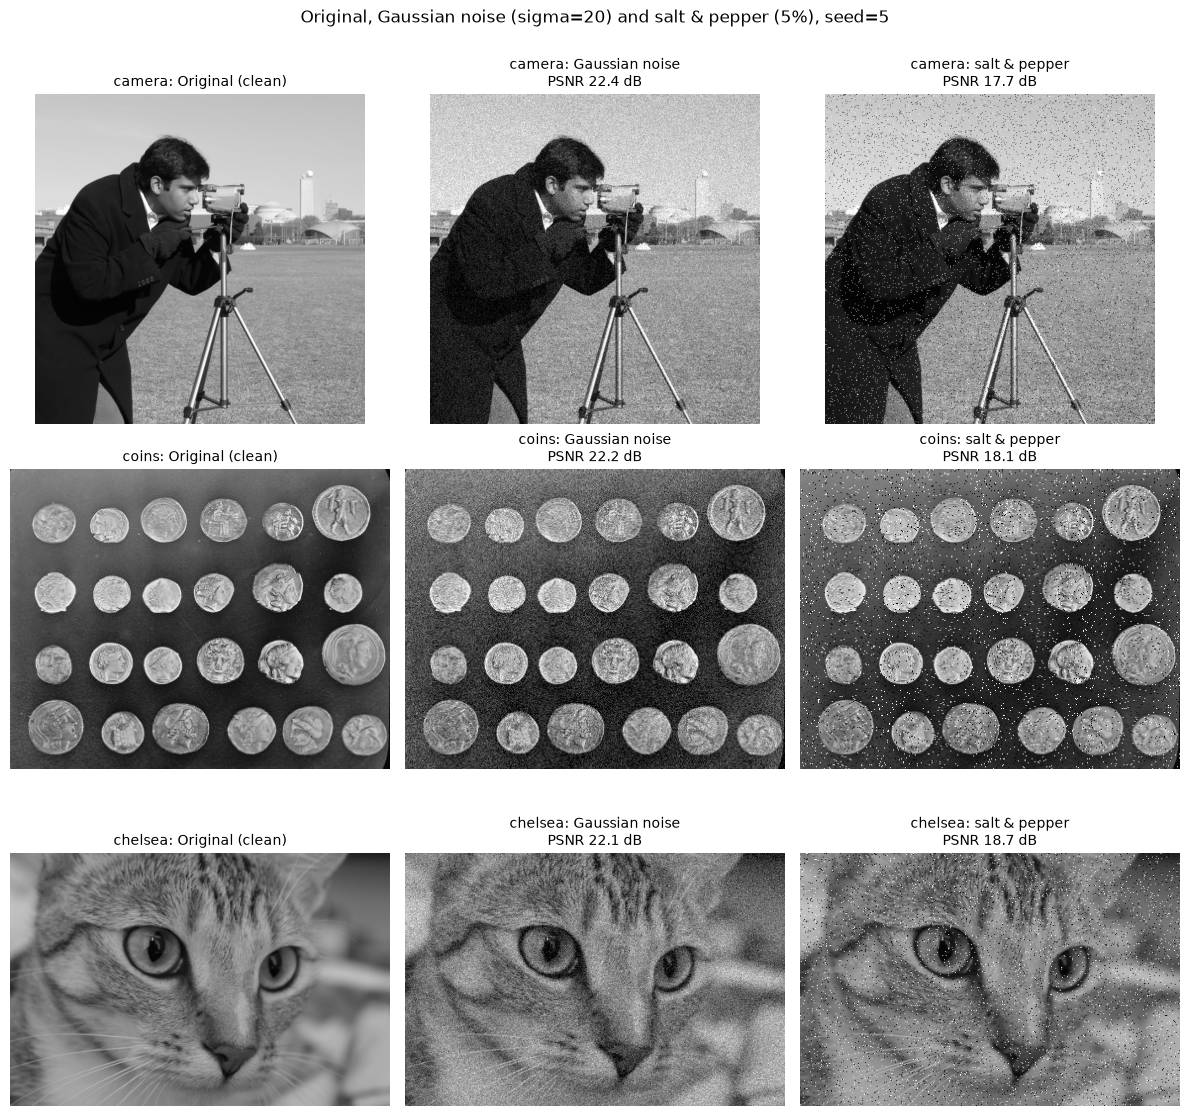

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11.5))
for r, n in enumerate(names):
    panels = [("Original (clean)", images[n])]
    for nt in NOISE_TYPES:
        panels.append((f"{nt}\nPSNR {psnr(images[n], noisy[(n, nt)]):.1f} dB", noisy[(n, nt)]))
    for c, (label, img) in enumerate(panels):
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{n}: {label}", fontsize=10); axes[r, c].axis("off")
plt.suptitle("Original, Gaussian noise (sigma=20) and salt & pepper (5%), seed=5", y=1.0)
plt.tight_layout(); plt.show()

### 7.2 Mean vs Gaussian vs median (3×3) on every noisy image
Titles show the PSNR **against the clean original**, including for the noisy input itself.

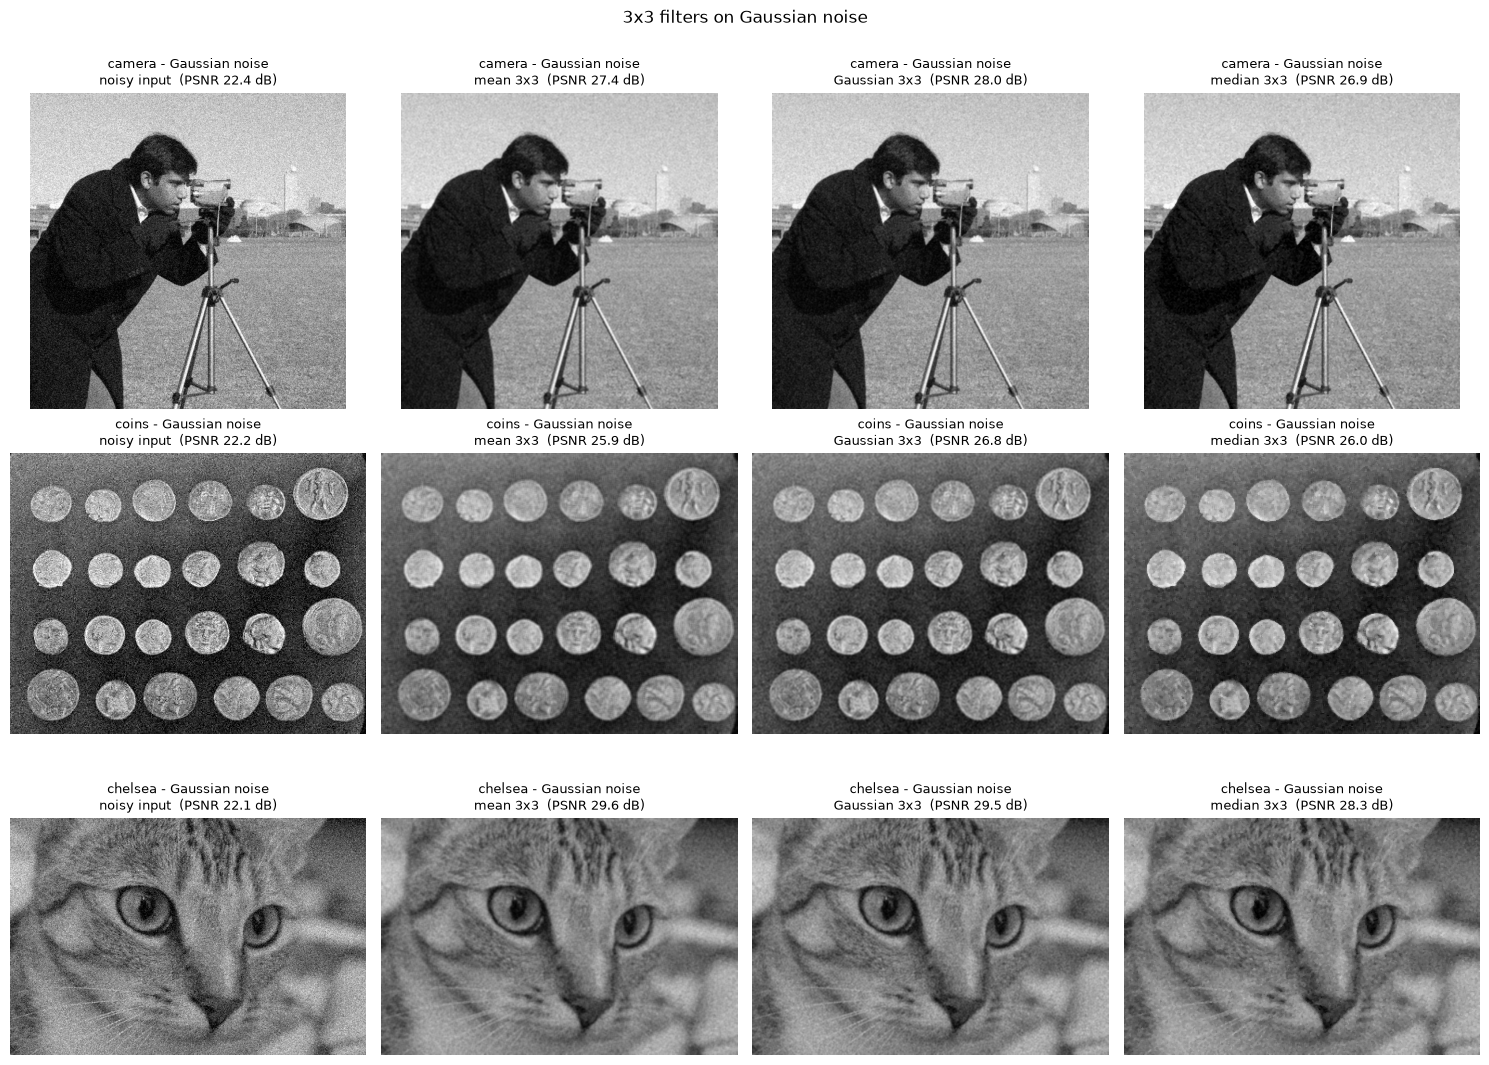

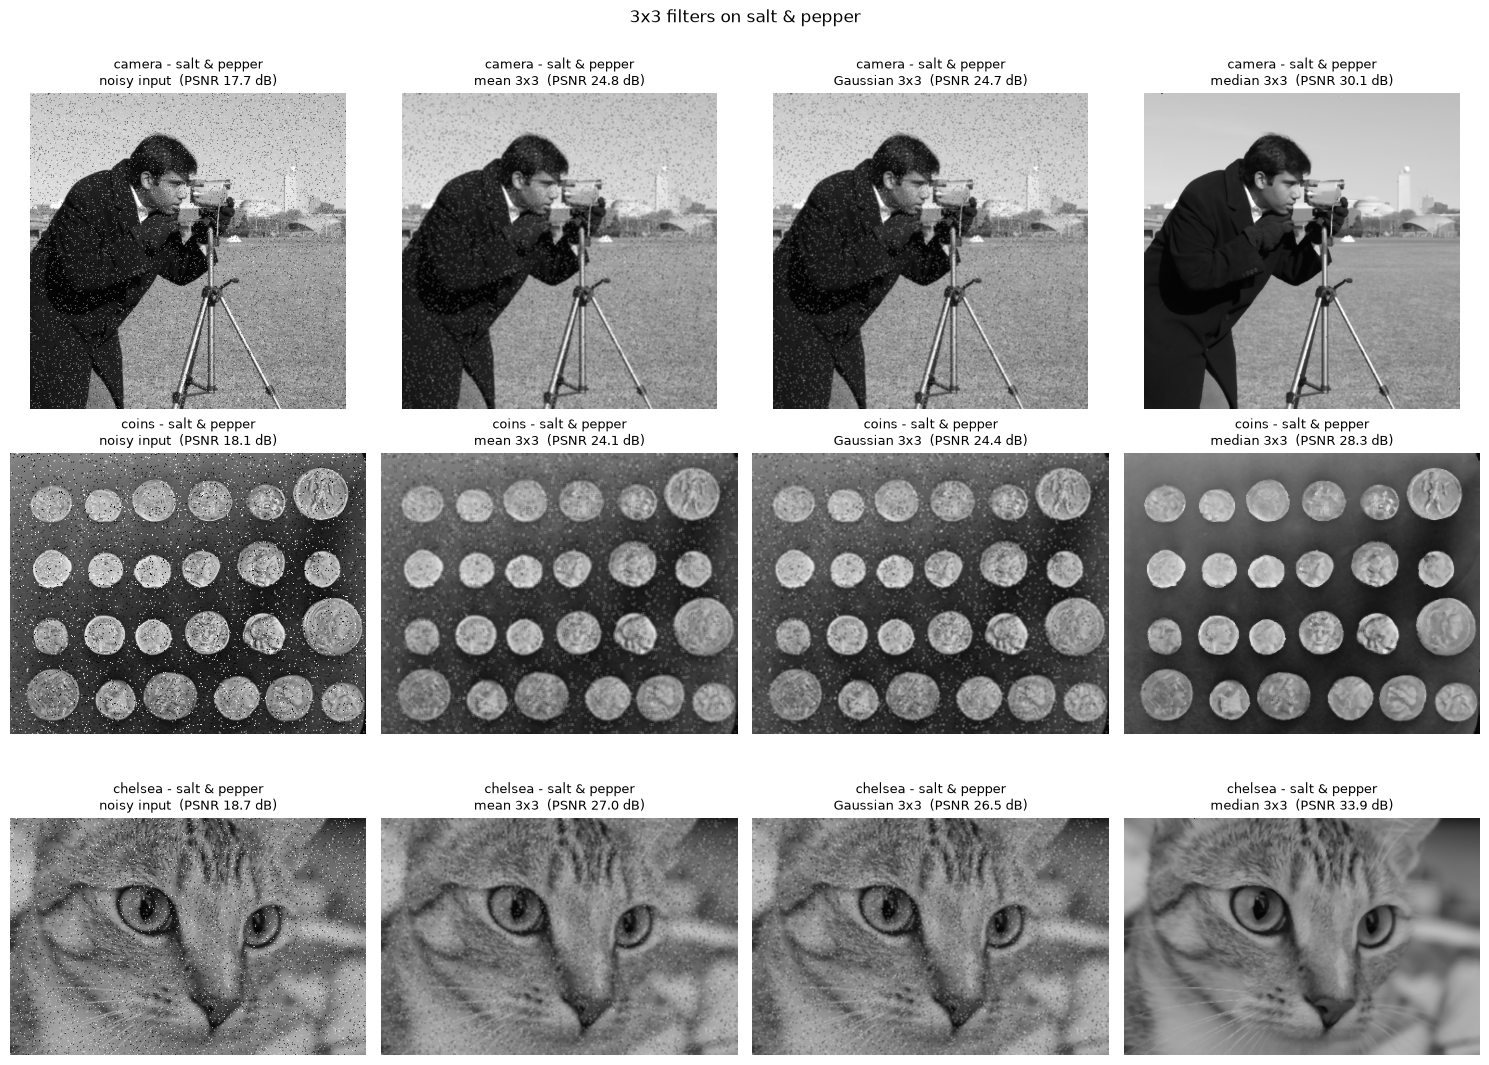

PSNR (dB) against the CLEAN original, 3x3 filters
image    noise             noisy    mean  Gaussian  median
camera   Gaussian noise    22.40   27.37     27.99   26.93
camera   salt & pepper     17.68   24.84     24.73   30.08
coins    Gaussian noise    22.20   25.86     26.79   25.98
coins    salt & pepper     18.09   24.09     24.37   28.33
chelsea  Gaussian noise    22.12   29.55     29.46   28.28
chelsea  salt & pepper     18.66   26.99     26.51   33.90


In [9]:
for nt in NOISE_TYPES:
    fig, axes = plt.subplots(3, 4, figsize=(15, 11))
    for r, n in enumerate(names):
        panels = [(f"noisy input", noisy[(n, nt)])] + [(f"{f} 3x3", filtered[(n, nt, f, 3)]) for f in FILTERS]
        for c, (label, img) in enumerate(panels):
            axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255)
            axes[r, c].set_title(f"{n} - {nt}\n{label}  (PSNR {psnr(images[n], img):.1f} dB)", fontsize=9)
            axes[r, c].axis("off")
    plt.suptitle(f"3x3 filters on {nt}", y=1.0)
    plt.tight_layout(); plt.show()

print("PSNR (dB) against the CLEAN original, 3x3 filters")
print(f"{'image':8s} {'noise':15s} {'noisy':>7s} {'mean':>7s} {'Gaussian':>9s} {'median':>7s}")
for n in names:
    for nt in NOISE_TYPES:
        row = [psnr(images[n], noisy[(n, nt)])] + [psnr(images[n], filtered[(n, nt, f, 3)]) for f in FILTERS]
        print(f"{n:8s} {nt:15s} {row[0]:7.2f} {row[1]:7.2f} {row[2]:9.2f} {row[3]:7.2f}")

### 7.3 Filter × kernel size (3×3, 5×5, 7×7) on the noisiest image
The "noisiest" image is the noisy image with the **lowest PSNR against its clean original**.

PSNR of every noisy image vs its clean original:
  camera   salt & pepper    17.68 dB
  coins    salt & pepper    18.09 dB
  chelsea  salt & pepper    18.66 dB
  chelsea  Gaussian noise   22.12 dB
  coins    Gaussian noise   22.20 dB
  camera   Gaussian noise   22.40 dB

Noisiest image: camera with salt & pepper  (17.68 dB)


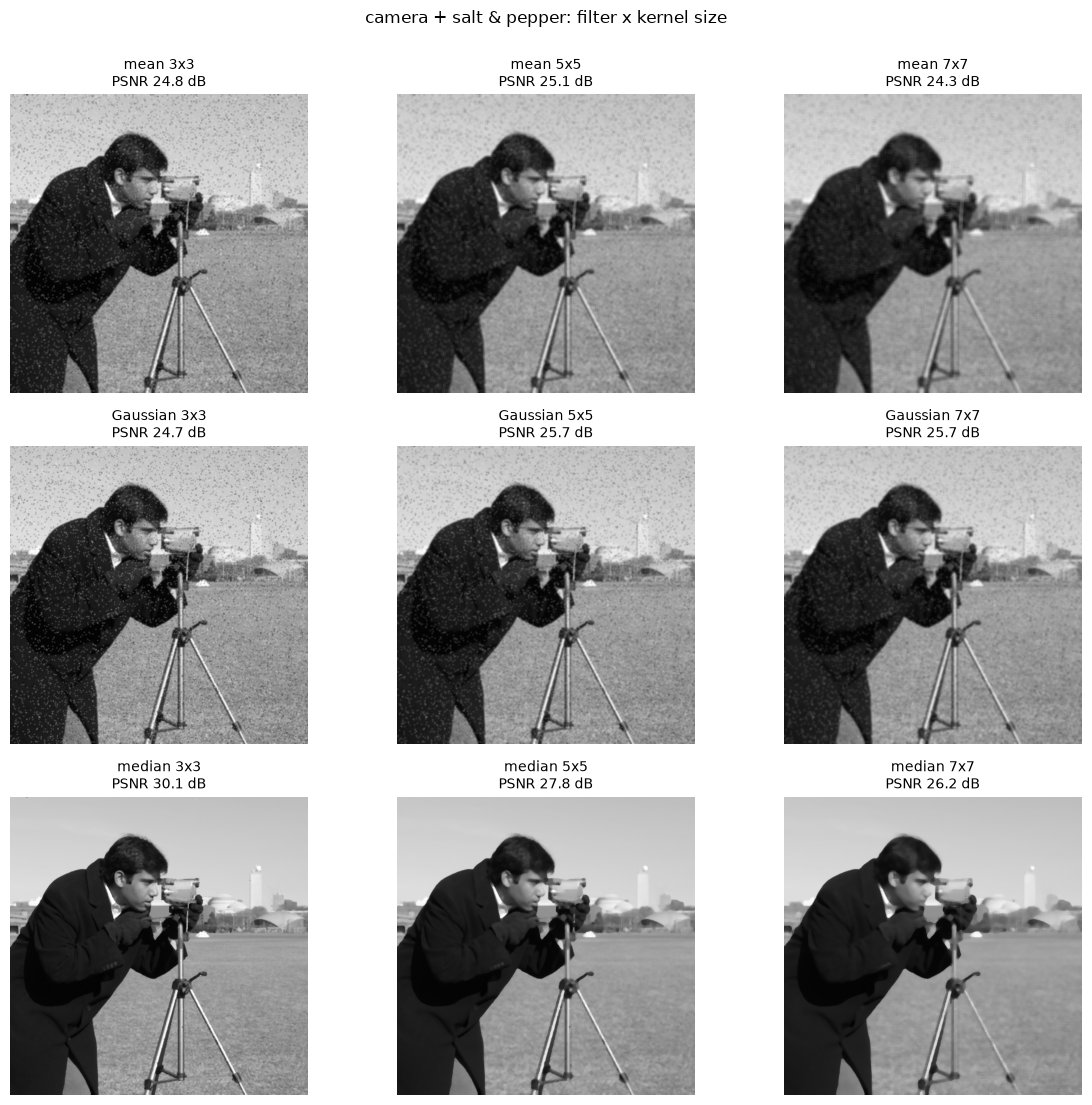


PSNR (dB) vs clean original - camera, salt & pepper
filter        3x3     5x5     7x7
mean        24.84   25.09   24.26
Gaussian    24.73   25.66   25.67
median      30.08   27.85   26.24


In [10]:
scores = {key: psnr(images[key[0]], img) for key, img in noisy.items()}
noisiest = min(scores, key=scores.get)
n, nt = noisiest
print("PSNR of every noisy image vs its clean original:")
for key, s in sorted(scores.items(), key=lambda kv: kv[1]):
    print(f"  {key[0]:8s} {key[1]:15s} {s:6.2f} dB")
print(f"\nNoisiest image: {n} with {nt}  ({scores[noisiest]:.2f} dB)")

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for r, f in enumerate(FILTERS):
    for c, k in enumerate(VALID_SIZES):
        out = filtered[(n, nt, f, k)]
        axes[r, c].imshow(out, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{f} {k}x{k}\nPSNR {psnr(images[n], out):.1f} dB", fontsize=10); axes[r, c].axis("off")
plt.suptitle(f"{n} + {nt}: filter x kernel size", y=1.0)
plt.tight_layout(); plt.show()

print(f"\nPSNR (dB) vs clean original - {n}, {nt}")
print(f"{'filter':9s}" + "".join(f"{str(k) + 'x' + str(k):>8s}" for k in VALID_SIZES))
for f in FILTERS:
    print(f"{f:9s}" + "".join(f"{psnr(images[n], filtered[(n, nt, f, k)]):8.2f}" for k in VALID_SIZES))

### 7.4 Close-up of a sharp edge (mean vs Gaussian) and of fine detail
To compare how mean and Gaussian treat a sharp edge without noise getting in the way, a clean, strong step edge (flat on both sides, very different brightness) of the `camera` image is located automatically and filtered at 3×3 and 5×5. The profile is a single row through that edge.

Step edge found in the clean camera image at row 201, column 188; close-up window rows 189-213, columns 176-200


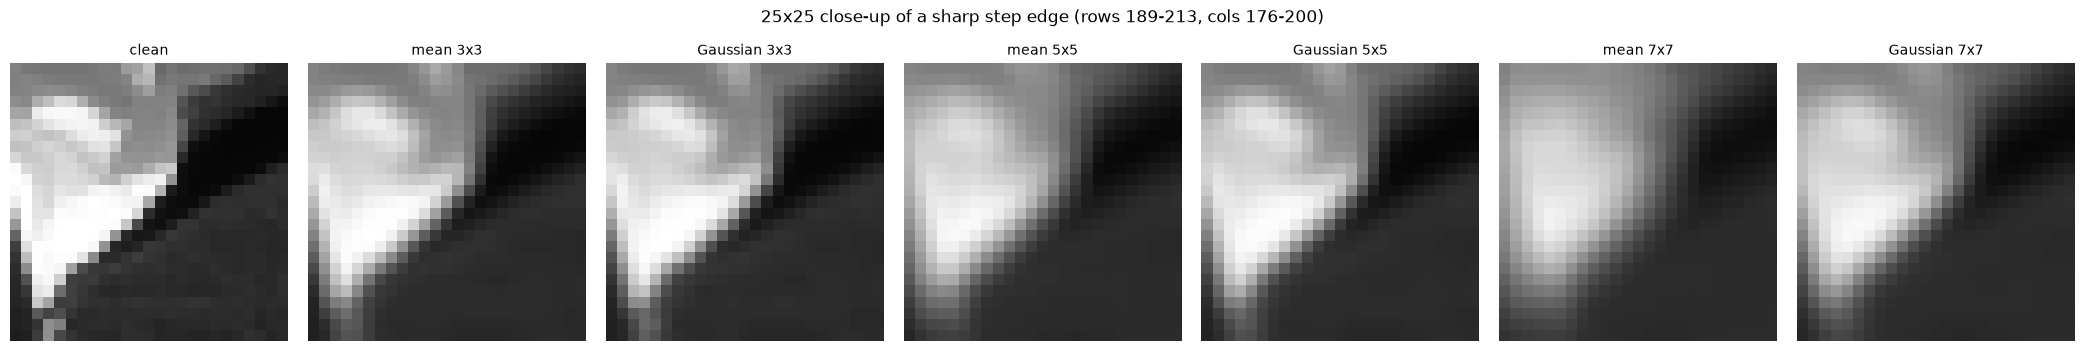

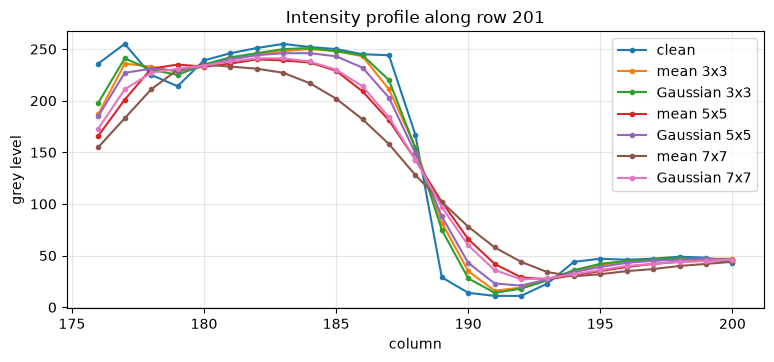

Edge width = number of pixels between 10% and 90% of the step height (row 201 columns 180 to 196 )
  clean            1 px
  mean 3x3         3 px
  Gaussian 3x3     3 px
  mean 5x5         5 px
  Gaussian 5x5     3 px
  mean 7x7         7 px
  Gaussian 7x7     5 px


In [11]:
cam = images["camera"]
# Find the cleanest big STEP edge: flat on both sides (small spread) but very different average brightness
f = lambda a: cv2.blur(a, (5, 1), borderType=cv2.BORDER_REFLECT_101)      # 5-pixel horizontal window
c64 = cam.astype(np.float64)
m = f(c64); sd = np.sqrt(np.maximum(f(c64 ** 2) - m ** 2, 0))
score = np.full(cam.shape, -1e9)
for x in range(8, cam.shape[1] - 8):
    mL, mR, sL, sR = m[:, x - 3], m[:, x + 3], sd[:, x - 3], sd[:, x + 3]   # windows just left / right of column x
    score[:, x] = np.abs(mR - mL) - 2 * (sL + sR)
score[:30, :] = score[-30:, :] = -1e9
ey, ex = np.unravel_index(np.argmax(score), score.shape)
y0, y1, x0, x1 = ey - 12, ey + 13, ex - 12, ex + 13
print(f"Step edge found in the clean camera image at row {ey}, column {ex}; close-up window rows {y0}-{y1 - 1}, columns {x0}-{x1 - 1}")

variants = {"clean": cam}
for k in (3, 5, 7):
    variants[f"mean {k}x{k}"] = mean_filter(cam, k)
    variants[f"Gaussian {k}x{k}"] = gaussian_filter(cam, k)

fig, axes = plt.subplots(1, 7, figsize=(21, 3.4))
for ax, (label, img) in zip(axes, variants.items()):
    ax.imshow(img[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(label, fontsize=10); ax.axis("off")
plt.suptitle(f"25x25 close-up of a sharp step edge (rows {y0}-{y1 - 1}, cols {x0}-{x1 - 1})", y=1.02)
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 3.6))
for label, img in variants.items():
    plt.plot(range(x0, x1), img[ey, x0:x1], marker="o", ms=3, label=label)
plt.xlabel("column"); plt.ylabel("grey level"); plt.title(f"Intensity profile along row {ey}")
plt.grid(alpha=0.3); plt.legend(); plt.show()

def width_10_90(profile):
    """Pixels strictly between 10% and 90% of the step, using the 3 outermost pixels on each side as the plateaus."""
    p = profile.astype(float); hi, lo = p[:3].mean(), p[-3:].mean()
    t = (p - lo) / (hi - lo)
    return int(np.sum((t > 0.1) & (t < 0.9)))
print("Edge width = number of pixels between 10% and 90% of the step height (row", ey, "columns", ex - 8, "to", ex + 8, ")")
for label, img in variants.items():
    print(f"  {label:15s} {width_10_90(img[ey, ex - 8:ex + 9]):2d} px")

### 7.5 Flat-region check: residual error in the sky of the `camera` image
A flat region shows clearly how much noise a filter leaves behind. Region: the sky at the top of `camera` (rows 5–59, columns 10–499). Errors are measured **against the clean original** (R6), for the 3×3 filters.

In [12]:
ys, xs = slice(5, 60), slice(10, 500)
clean_patch = images["camera"][ys, xs].astype(np.float64)
print(f"clean sky patch: mean {clean_patch.mean():.1f}, std {clean_patch.std():.1f}  ({clean_patch.shape[0]}x{clean_patch.shape[1]} pixels)")
for nt in NOISE_TYPES:
    print(f"\n{nt}")
    for label, img in [("noisy input", noisy[("camera", nt)])] + [(f"{f} 3x3", filtered[("camera", nt, f, 3)]) for f in FILTERS]:
        err = img[ys, xs].astype(np.float64) - clean_patch
        print(f"  {label:14s} RMS error {np.sqrt((err ** 2).mean()):6.2f}   pixels off by more than 40 grey levels: {100 * np.mean(np.abs(err) > 40):5.2f} %")

clean sky patch: mean 198.9, std 4.1  (55x490 pixels)

Gaussian noise
  noisy input    RMS error  19.94   pixels off by more than 40 grey levels:  4.23 %
  mean 3x3       RMS error   6.66   pixels off by more than 40 grey levels:  0.00 %
  Gaussian 3x3   RMS error   7.46   pixels off by more than 40 grey levels:  0.00 %
  median 3x3     RMS error   8.16   pixels off by more than 40 grey levels:  0.00 %

salt & pepper
  noisy input    RMS error  33.37   pixels off by more than 40 grey levels:  5.21 %
  mean 3x3       RMS error  11.65   pixels off by more than 40 grey levels:  1.83 %
  Gaussian 3x3   RMS error  12.94   pixels off by more than 40 grey levels:  2.99 %
  median 3x3     RMS error   0.70   pixels off by more than 40 grey levels:  0.00 %


## 8. Observations (answers use the figures and tables above, judged against the clean original – R6)

**1. Gaussian noise – which filter looks best and which worst?**  
*Best: the Gaussian filter.* In the table of section 7.2 it has the highest PSNR against the clean original on `camera` (28.0 dB vs 27.4 mean and 26.9 median) and on `coins` (26.8 vs 25.9 and 26.0); on `chelsea` mean and Gaussian are practically tied (29.6 vs 29.5 dB). In the flat sky of `camera` (section 7.5) the plain mean actually leaves slightly less noise (RMS error 6.7 vs 7.5), but the Gaussian keeps edges sharper (see answer 3), which is why it scores higher overall. *Worst: the median.* It has the lowest PSNR on `camera` (26.9 dB) and `chelsea` (28.3 dB) and the largest residual error in the sky (RMS 8.2): the median does not average, so it cannot cancel random Gaussian fluctuations. On `coins` mean and median are almost equal (25.9 vs 26.0 dB), so the median is the clear loser on two of the three images.

**2. Salt-and-pepper noise – which filter is best, and why do the other two fail?**  
*Best: the median* – 30.1 dB on `camera`, 28.3 dB on `coins`, 33.9 dB on `chelsea`, 4–7 dB above the other two. In the `camera` sky (section 7.5) the median leaves an RMS error of only 0.70 and not a single pixel off by more than 40 grey levels, whereas mean and Gaussian still have 1.8 % and 3.0 % of the pixels badly wrong. *Why mean and Gaussian fail:* a 0 or 255 pixel is an extreme outlier, and a weighted average always includes it. Dry-run Exercise 1 shows this: a 255 spike on a 40 background becomes 64 after the mean and 94 after the Gaussian (the centre weight is 4/16), so the spike is only smeared into a grey blob. This is visible as dark and bright dots that remain as soft spots in the sky, the coat and the grass of the `camera` panels (mean 3×3 and Gaussian 3×3 in the second grid of 7.2). The median sorts the neighbourhood and an outlier lands at the end of the list, so the middle value (40 in the exercise) ignores it completely.

**3. Mean vs Gaussian on a sharp edge**  
Close-up of section 7.4 (clean `camera`, rows 189–213, columns 176–200: the bright diagonal edge of the camera against the dark coat) and the profile along row 201. A step that is 1 pixel wide in the clean image becomes 3 px with both 3×3 filters, but at 5×5 the mean makes it **5 px** wide while the Gaussian keeps it at **3 px**, and at 7×7 the widths are 7 px (mean) vs 5 px (Gaussian). The mean gives every neighbour the same weight, so pixels from the other side of the edge count as much as the centre pixel and the edge becomes a long, gentle ramp. The Gaussian gives the centre pixel the largest weight, so the edge stays steeper. This is why the Gaussian has the better PSNR on `camera` and `coins`.

**4. What happens to fine detail at 7×7?**  
Fine detail is lost. In the filter × size grid of 7.3 (`camera`), the mean 7×7 panel shows the tripod legs as wide, faint bands, the white tower on the horizon (right of the cameraman's head) becomes faint, and the face and camera are heavily blurred; in the 7×7 close-up of 7.4 the bright shape has lost its outline. Gaussian 7×7 is clearly sharper than mean 7×7 but still soft. The median 7×7 keeps the main edges (the coat outline, the tripod legs) but removes or rounds off the smallest features. The numbers confirm that larger is not better: mean falls from 25.1 dB (5×5) to 24.3 dB (7×7) and median falls steadily from 30.1 to 27.8 to 26.2 dB, because the detail destroyed by the larger window costs more than the extra noise removed.

**5. Why must the kernel size be odd?**  
An odd kernel has one centre pixel with the same number of neighbours (k//2) above, below, left and right, so the output value belongs exactly to the pixel at the centre, and padding the border by k//2 on every side is symmetric. With an even size (for example 4×4) there is no centre pixel: the window would sit half a pixel off, the result would be shifted by half a pixel, and the padding would have to be uneven. The 3×3 windows used in the two dry-run exercises (centre at position (1, 1)) show the idea, and section 5 shows OpenCV refusing `cv2.medianBlur(img, 4)` with an assertion error, while the lab's rule R4 allows only 3, 5 and 7.

## 9. Viva preparation

**Q1. What is a kernel?**  
A kernel (or filter mask) is a small odd-sized matrix of weights, for example 3×3. It is slid over the image; at every pixel the neighbourhood is multiplied element by element with the weights and the products are added to give the new pixel value. The weights decide what the filter does: all weights 1/9 gives a mean (blur), the 1-2-1 / 2-4-2 / 1-2-1 ÷ 16 weights give a Gaussian blur.

**Q2. Why does the median remove a 255 spike but the mean does not?**  
In Exercise 1 the neighbourhood is eight 40s and one 255. The mean adds everything, so the spike contributes 255/9 and the result is 64 – the spike is only spread out. The median sorts the nine values (40, 40, …, 40, 255) and takes the middle one, which is 40: an extreme value always sits at the end of the sorted list and never becomes the middle, so it has no influence at all as long as fewer than half the pixels in the window are corrupted.

**Q3. Why do we pad the border before filtering?**  
At the border a k×k window hangs partly outside the image, so some neighbours do not exist. Padding (here with reflect padding, which mirrors the pixels next to the edge, as in Exercise 2, where the neighbourhood of pixel (0, 0) became [[50, 40, 50], [20, 10, 20], [50, 40, 50]]) supplies those missing values. Then every pixel, including the border pixels, gets a full window and the output has the same size as the input (rule R1), instead of shrinking or leaving a ring of unfiltered pixels.

## 10. Final check

In [13]:
for n in names:
    assert np.array_equal(images[n], backup[n]), f"{n} was modified!"
print("All three original test images are unchanged: OK")

All three original test images are unchanged: OK
